In [1]:

# Install TensorFlow Datasets
!pip install -q tensorflow-datasets

# Import required libraries
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

# Check library versions
print("TensorFlow Version:", tf.__version__)
print("TensorFlow Datasets Version:", tfds.__version__)

# Check GPU availability
print("Available GPU:", tf.config.list_physical_devices('GPU'))

print("\nEnvironment setup completed successfully!")


TensorFlow Version: 2.21.0
TensorFlow Datasets Version: 4.9.10
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Environment setup completed successfully!


In [3]:

!pip install -q --upgrade importlib_resources

print("Missing dependency installed successfully!")


Missing dependency installed successfully!


In [4]:

# Remove the incomplete EMNIST dataset folder
!rm -rf /root/tensorflow_datasets/emnist/letters/3.1.0

print("Incomplete dataset cache cleared!")


Incomplete dataset cache cleared!


In [3]:

# Import required libraries
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)


All libraries imported successfully!
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10


In [4]:

# Load EMNIST Letters training dataset
train_dataset, dataset_info = tfds.load(
    'emnist/letters',
    split='train',
    as_supervised=True,
    with_info=True
)

# Load EMNIST Letters testing dataset
test_dataset = tfds.load(
    'emnist/letters',
    split='test',
    as_supervised=True
)

# Display dataset information
print("EMNIST dataset loaded successfully!")

print("Training samples:",
      dataset_info.splits['train'].num_examples)

print("Testing samples:",
      dataset_info.splits['test'].num_examples)

print("Image shape:",
      dataset_info.features['image'].shape)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.RF80MN_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.RF80MN_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.
EMNIST dataset loaded successfully!
Training samples: 88800
Testing samples: 14800
Image shape: (28, 28, 1)


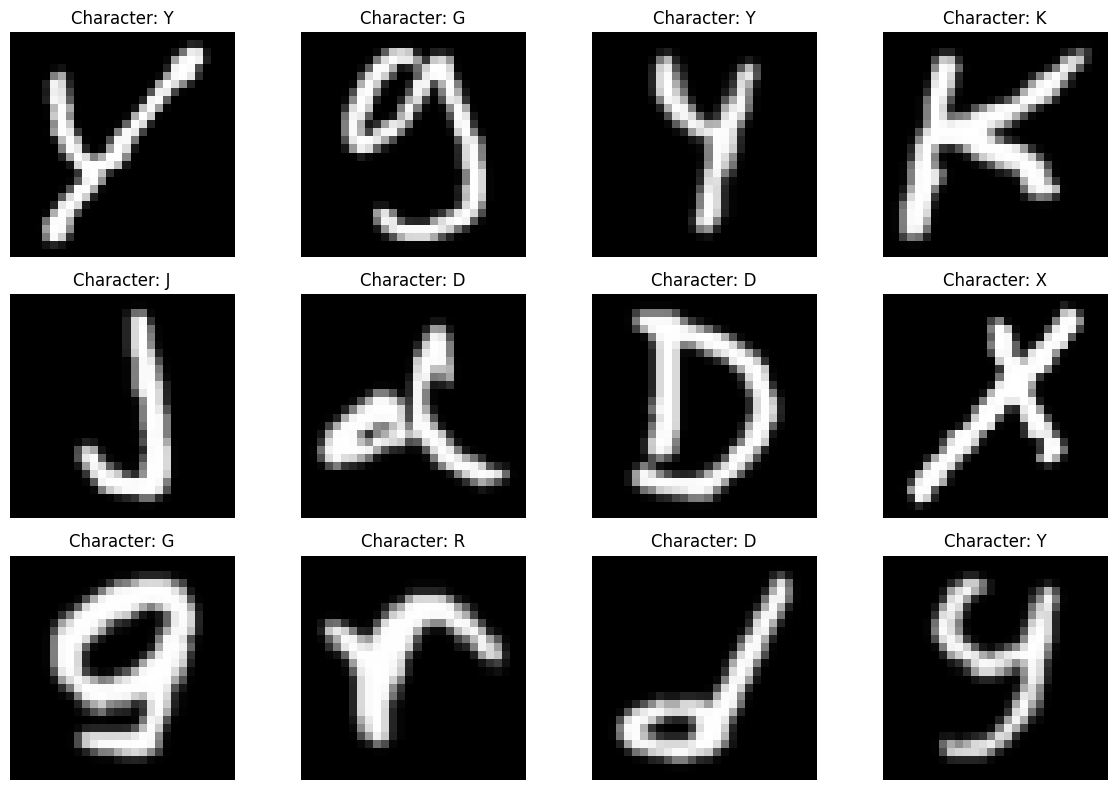

In [5]:

# Visualize 12 handwritten alphabet samples

plt.figure(figsize=(12, 8))

for index, (image, label) in enumerate(train_dataset.take(12)):

    # Correct image orientation
    image = tf.transpose(image, perm=[1, 0, 2])

    # Convert label into alphabet
    label = int(label.numpy())
    character = chr(label + 64)

    # Display image
    plt.subplot(3, 4, index + 1)
    plt.imshow(tf.squeeze(image), cmap='gray')
    plt.title(f"Character: {character}")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [6]:

# Check sample labels

print("First 20 numerical labels:")

for image, label in train_dataset.take(20):
    label = int(label.numpy())
    print(f"Label: {label} --> Character: {chr(label + 64)}")


First 20 numerical labels:
Label: 25 --> Character: Y
Label: 7 --> Character: G
Label: 25 --> Character: Y
Label: 11 --> Character: K
Label: 10 --> Character: J
Label: 4 --> Character: D
Label: 4 --> Character: D
Label: 24 --> Character: X
Label: 7 --> Character: G
Label: 18 --> Character: R
Label: 4 --> Character: D
Label: 25 --> Character: Y
Label: 22 --> Character: V
Label: 2 --> Character: B
Label: 4 --> Character: D
Label: 13 --> Character: M
Label: 16 --> Character: P
Label: 14 --> Character: N
Label: 21 --> Character: U
Label: 11 --> Character: K


In [7]:

# Image preprocessing function

def preprocess_image(image, label):

    # Correct EMNIST image orientation
    image = tf.transpose(image, perm=[1, 0, 2])

    # Convert pixel values from 0-255 to 0-1
    image = tf.cast(image, tf.float32) / 255.0

    # Convert labels from 1-26 to 0-25
    label = tf.cast(label, tf.int64) - 1

    return image, label


print("Image preprocessing function created successfully!")


Image preprocessing function created successfully!


In [8]:

# Shuffle the training dataset
shuffled_train = train_dataset.shuffle(
    buffer_size=10000,
    seed=42,
    reshuffle_each_iteration=False
)

# Split 10% for validation
validation_raw = shuffled_train.take(8880)
training_raw = shuffled_train.skip(8880)

# Define batch size
BATCH_SIZE = 128

# Prepare training dataset
train_ds = (
    training_raw
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Prepare validation dataset
val_ds = (
    validation_raw
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Prepare testing dataset
test_ds = (
    test_dataset
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset splitting and preprocessing completed!")


Dataset splitting and preprocessing completed!


In [9]:

# Get one batch of training images
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("First 10 encoded labels:", labels[:10].numpy())


Image batch shape: (128, 28, 28, 1)
Label batch shape: (128,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First 10 encoded labels: [ 8  8 16  3 25 24  7  9 18  8]


In [10]:

# Import required CNN layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

# Create CNN model
model = Sequential([

    # First convolutional layer
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation='relu',
        padding='same',
        input_shape=(28, 28, 1)
    ),

    # First max pooling layer
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional layer
    Conv2D(
        64,
        kernel_size=(3, 3),
        activation='relu',
        padding='same'
    ),

    # Second max pooling layer
    MaxPooling2D(pool_size=(2, 2)),

    # Third convolutional layer
    Conv2D(
        128,
        kernel_size=(3, 3),
        activation='relu',
        padding='same'
    ),

    # Convert feature maps into a one-dimensional vector
    Flatten(),

    # Fully connected layer
    Dense(128, activation='relu'),

    # Reduce overfitting
    Dropout(0.3),

    # Output layer for 26 English alphabets
    Dense(26, activation='softmax')
])

print("CNN model created successfully!")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN model created successfully!


In [11]:

# Compile the CNN model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [12]:

# Display CNN architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 898,970 (3.43 MB)

 Trainable params: 898,970 (3.43 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:

# Import training callbacks
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

# Reduce learning rate when improvement slows down
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.000001
)

# Save the best performing model
checkpoint = ModelCheckpoint(
    'best_emnist_cnn.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

# Combine callbacks
callbacks = [
    early_stopping,
    reduce_lr,
    checkpoint
]

print("Training callbacks configured successfully!")


Training callbacks configured successfully!


In [14]:

# Train the CNN model

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("CNN model training completed!")


Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 33s 33ms/step - accuracy: 0.7971 - loss: 0.6691 - val_accuracy: 0.9189 - val_loss: 0.2575 - learning_rate: 0.0010
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9052 - loss: 0.2929 - val_accuracy: 0.9271 - val_loss: 0.2185 - learning_rate: 0.0010
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9206 - loss: 0.2368 - val_accuracy: 0.9319 - val_loss: 0.1953 - learning_rate: 0.0010
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9300 - loss: 0.2039 - val_accuracy: 0.9320 - val_loss: 0.1916 - learning_rate: 0.0010
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9370 - loss: 0.1795 - val_accuracy: 0.9334 - val_loss: 0.1894 - learning_rate: 0.0010
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9432 - loss: 0.1602 - val_accuracy: 0.9392 - val_loss: 0.1839 - learning_rate: 0.0010
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9465 - loss: 0.146

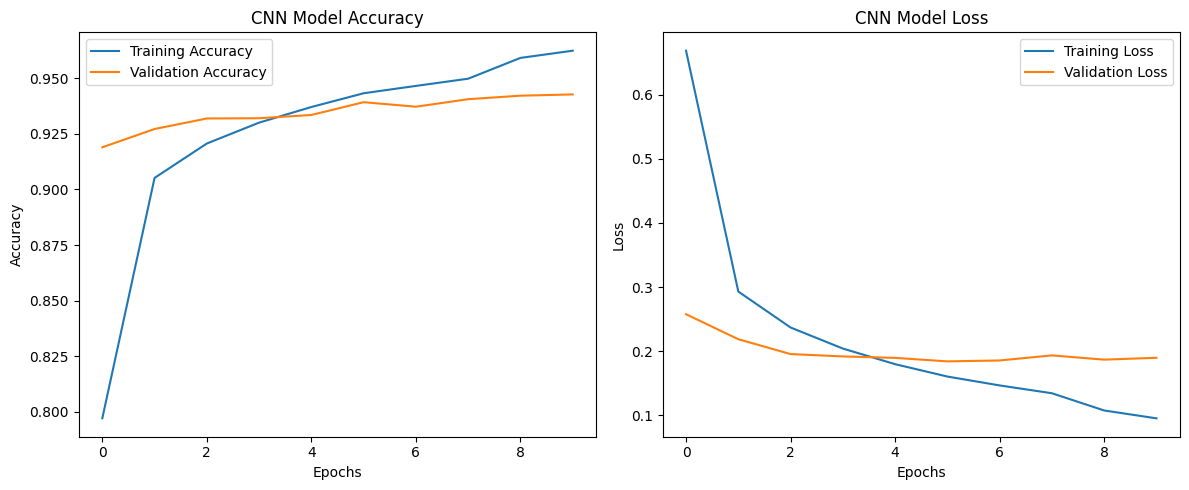

In [15]:

# Plot training and validation accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [16]:

# Evaluate CNN model using testing dataset

test_loss, test_accuracy = model.evaluate(test_ds)

print("\nModel Evaluation Results")
print("------------------------")

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


116/116 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.9264 - loss: 0.2279

Model Evaluation Results
------------------------
Test Loss: 0.2279
Test Accuracy: 92.64%


In [17]:

# Import evaluation metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Get actual labels from testing dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Generate predictions
y_probabilities = model.predict(test_ds)

# Convert probabilities into predicted classes
y_pred = np.argmax(y_probabilities, axis=1)

# Define alphabet classes
class_names = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# Generate classification report
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(26),
    target_names=class_names,
    zero_division=0
))


116/116 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step
              precision    recall  f1-score   support

           A       0.93      0.94      0.94       800
           B       0.98      0.97      0.97       800
           C       0.96      0.96      0.96       800
           D       0.94      0.94      0.94       800
           E       0.97      0.96      0.97       800
           F       0.98      0.96      0.97       800
           G       0.91      0.79      0.85       800
           H       0.95      0.96      0.95       800
           I       0.78      0.71      0.74       800
           J       0.97      0.94      0.95       800
           K       0.98      0.98      0.98       800
           L       0.74      0.81      0.77       800
           M       0.99      0.99      0.99       800
           N       0.97      0.95      0.96       800
           O       0.93      0.97      0.95       800
           P       0.99      0.98      0.98       800
           Q       0.83      0.88      

<Figure size 1500x1200 with 0 Axes>

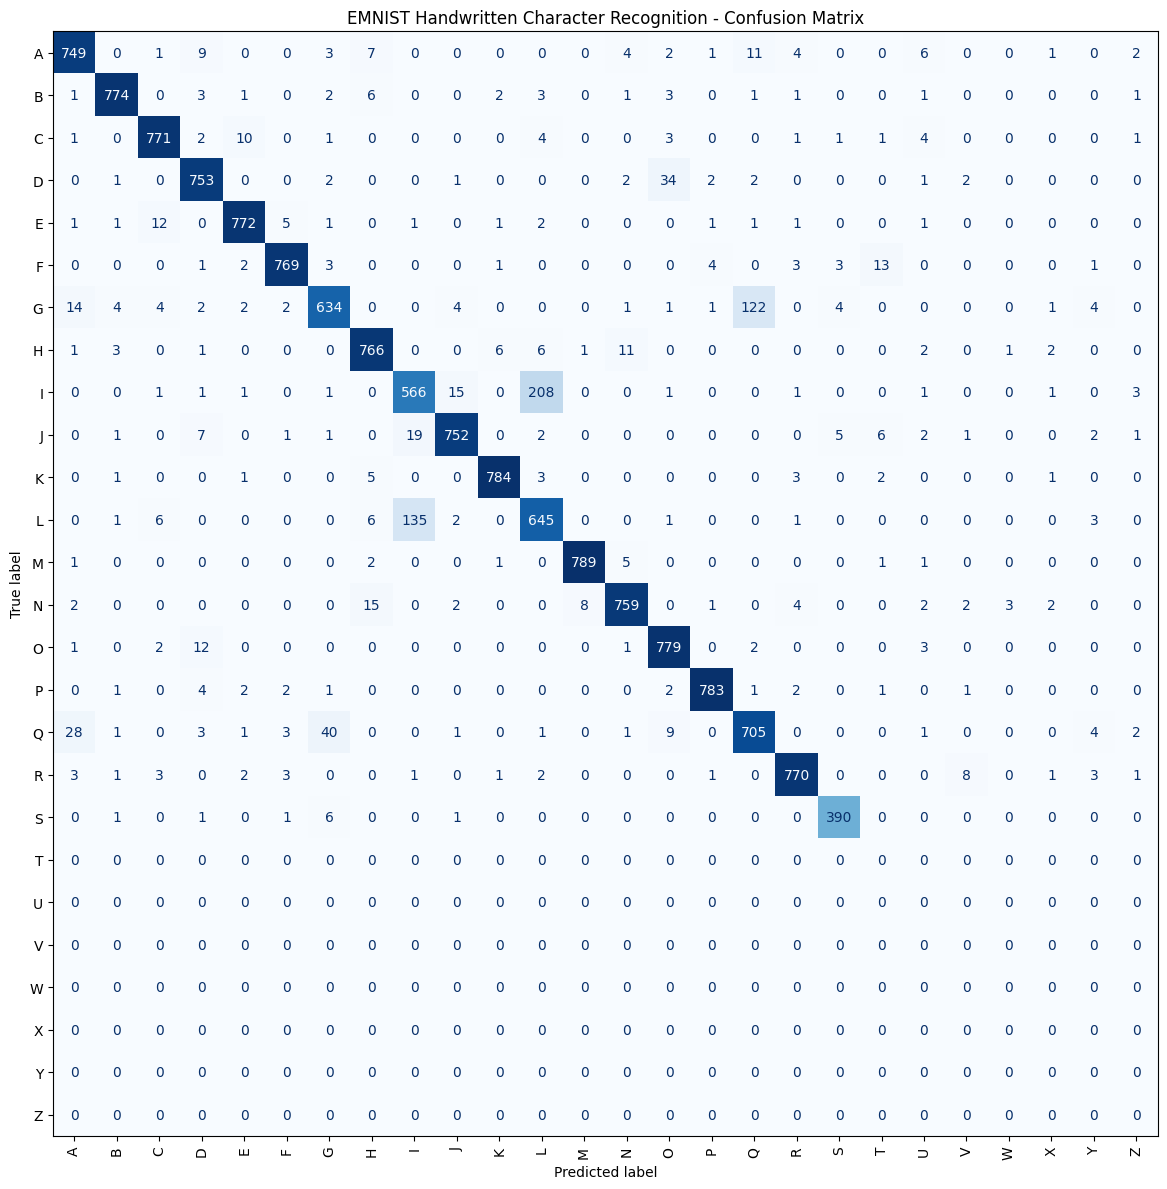

In [18]:

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(26)
)

# Display confusion matrix
plt.figure(figsize=(15, 12))

from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(15, 12))

display.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=90,
    colorbar=False,
    values_format='d'
)

plt.title("EMNIST Handwritten Character Recognition - Confusion Matrix")
plt.tight_layout()
plt.show()


In [19]:

# Save the trained CNN model

model.save("emnist_character_recognition.keras")

print("CNN model saved successfully!")


CNN model saved successfully!


In [20]:

from google.colab import files

# Upload your handwritten character image
uploaded = files.upload()

print("Image uploaded successfully!")


Saving WhatsApp Image 2026-11-10 at 4.02.11 PM.jpeg to WhatsApp Image 2026-11-10 at 4.02.11 PM.jpeg
Image uploaded successfully!


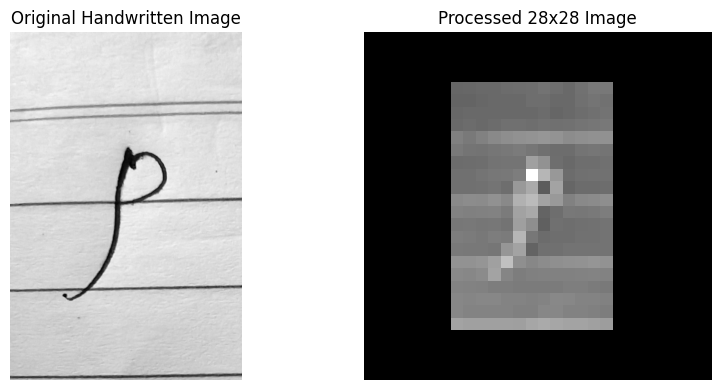

Predicted Character: D
Prediction Confidence: 9.32%


In [21]:

from PIL import Image
import io

# Read the uploaded image
file_name = next(iter(uploaded))

original_image = Image.open(
    io.BytesIO(uploaded[file_name])
).convert("L")

# Convert image into NumPy array
image_array = np.array(original_image)

# Invert white-paper images:
# EMNIST uses black background and white strokes
if image_array.mean() > 127:
    image_array = 255 - image_array

# Remove small background noise
image_array[image_array < 30] = 0

# Find character boundaries
coordinates = np.where(image_array > 30)

if len(coordinates[0]) == 0:
    raise ValueError("No handwritten character detected.")

# Crop the character
top, bottom = coordinates[0].min(), coordinates[0].max() + 1
left, right = coordinates[1].min(), coordinates[1].max() + 1

cropped = image_array[top:bottom, left:right]

# Resize while maintaining aspect ratio
character_image = Image.fromarray(cropped)

character_image.thumbnail(
    (20, 20),
    Image.Resampling.LANCZOS
)

# Place character at center of 28x28 canvas
canvas = Image.new("L", (28, 28), 0)

x_position = (28 - character_image.width) // 2
y_position = (28 - character_image.height) // 2

canvas.paste(character_image, (x_position, y_position))

# Normalize image
processed_image = np.array(canvas).astype("float32") / 255.0

# Reshape for CNN input
input_image = processed_image.reshape(1, 28, 28, 1)

# Predict character
predictions = model.predict(input_image, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_character = chr(predicted_index + 65)

confidence = predictions[predicted_index] * 100

# Display uploaded and processed images
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original Handwritten Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image.squeeze(), cmap="gray")
plt.title("Processed 28x28 Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display prediction
print("Predicted Character:", predicted_character)
print(f"Prediction Confidence: {confidence:.2f}%")


In [22]:

# Get top 3 predictions
top_three = np.argsort(predictions)[-3:][::-1]

print("Top 3 Character Predictions:")

for index in top_three:
    character = chr(index + 65)
    probability = predictions[index] * 100

    print(f"{character}: {probability:.2f}%")


Top 3 Character Predictions:
D: 9.32%
B: 8.60%
A: 8.05%


In [23]:

# Save final CNN model
model.save("Handwritten_Character_Recognition.keras")

# Download trained model
from google.colab import files

files.download("Handwritten_Character_Recognition.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

!pip install -q gradio

import gradio as gr

print("Gradio installed successfully!")


Gradio installed successfully!


In [25]:

from PIL import Image
import numpy as np

def predict_character(uploaded_image):

    if uploaded_image is None:
        return {}, None

    # Convert uploaded image to grayscale
    image = uploaded_image.convert("L")
    image_array = np.array(image)

    # Invert white background to black
    if image_array.mean() > 127:
        image_array = 255 - image_array

    # Remove minor background noise
    image_array[image_array < 30] = 0

    # Find character boundaries
    coordinates = np.where(image_array > 30)

    if len(coordinates[0]) == 0:
        return {"No character detected": 1.0}, None

    top, bottom = coordinates[0].min(), coordinates[0].max() + 1
    left, right = coordinates[1].min(), coordinates[1].max() + 1

    # Crop handwritten character
    cropped = image_array[top:bottom, left:right]

    # Resize while maintaining aspect ratio
    character = Image.fromarray(cropped)
    character.thumbnail((20, 20), Image.Resampling.LANCZOS)

    # Place character in 28x28 canvas
    canvas = Image.new("L", (28, 28), 0)

    x = (28 - character.width) // 2
    y = (28 - character.height) // 2

    canvas.paste(character, (x, y))

    # Normalize and reshape
    processed = np.array(canvas).astype("float32") / 255.0
    input_image = processed.reshape(1, 28, 28, 1)

    # Make prediction
    predictions = model.predict(input_image, verbose=0)[0]

    # Prepare top three predictions
    top_indices = np.argsort(predictions)[-3:][::-1]

    result = {
        chr(index + 65): float(predictions[index])
        for index in top_indices
    }

    return result, canvas

print("Prediction function created successfully!")


Prediction function created successfully!


In [26]:

# Create Gradio interface

demo = gr.Interface(
    fn=predict_character,

    inputs=gr.Image(
        type="pil",
        label="Upload Handwritten Alphabet"
    ),

    outputs=[
        gr.Label(
            num_top_classes=3,
            label="Predicted Characters"
        ),
        gr.Image(
            type="pil",
            label="Processed 28x28 Image"
        )
    ],

    title="Handwritten Character Recognition",
    description=(
        "Upload a handwritten English alphabet image. "
        "Our CNN model will predict the character."
    )
)

# Launch application
demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://dc5a5df69616a0358f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio/flagged/dataset1.csv
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://dc5a5df69616a0358f.gradio.live


In [28]:

import os

# Check whether the best model checkpoint already exists
files_to_check = [
    "best_emnist_cnn.keras",
    "Handwritten_Character_Recognition.keras"
]

for file_name in files_to_check:
    if os.path.exists(file_name):
        size_mb = os.path.getsize(file_name) / (1024 * 1024)
        print(f"Found: {file_name}")
        print(f"File size: {size_mb:.2f} MB")
    else:
        print(f"Not found: {file_name}")


Found: best_emnist_cnn.keras
File size: 10.33 MB
Found: Handwritten_Character_Recognition.keras
File size: 10.33 MB


In [30]:
from google.colab import files

files.download("/content/Handwritten_Character_Recognition.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>